# 03 – Bivariate Analysis and Conclusions

Objective: analyse how each candidate feature relates to log(PRICE), rank the most predictive variables, identify non-linear patterns, detect multicollinearity, and define the final feature set and modelling strategy.

Input: data/processed/listings_02.parquet (output of notebook 02).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_02.parquet")

df["log_price"] = np.log(df["PRICE"])
print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"log(PRICE) — mean: {df['log_price'].mean():.2f}, std: {df['log_price'].std():.2f}")

Loaded: 75,795 rows × 39 columns
log(PRICE) — mean: 12.54, std: 0.76


## 1. Continuous features vs log(PRICE)

For each continuous feature, we plot the scatter against log(PRICE) with a linear trend line and report the Pearson correlation coefficient (r). This helps identify which features have strong linear relationships with the target and which may need non-linear transformations or tree-based models.

In [2]:
readable = {
    "CONSTRUCTEDAREA": "Constructed area (m2)",
    "CADCONSTRUCTIONYEAR": "Construction year",
    "DISTANCE_TO_CITY_CENTER": "Distance to city centre (km)",
    "DISTANCE_TO_METRO": "Distance to nearest metro (km)",
}

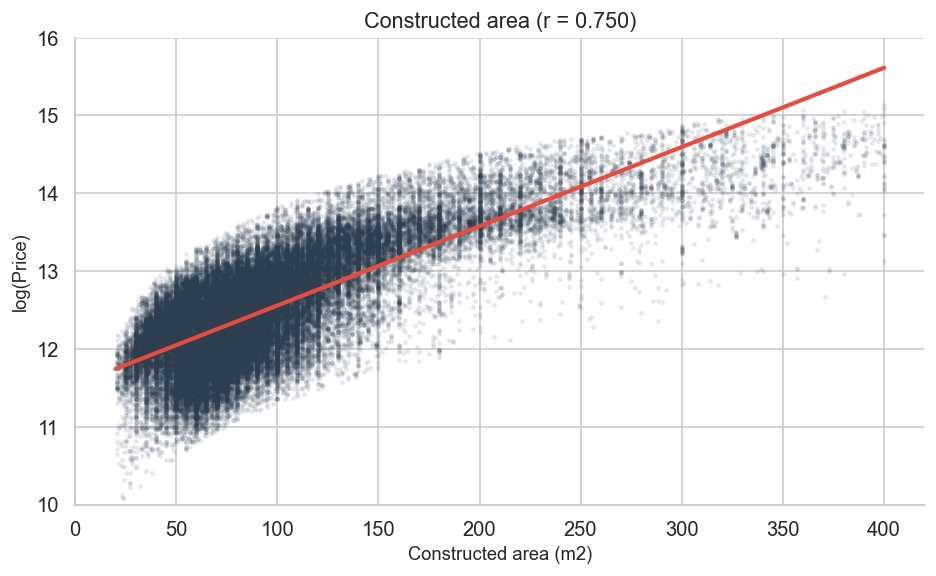

In [3]:
# Constructed area vs log(PRICE)
r = df["CONSTRUCTEDAREA"].corr(df["log_price"])
subset = df[df["CONSTRUCTEDAREA"] <= 400]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(subset["CONSTRUCTEDAREA"], subset["log_price"], alpha=0.08, s=4, color="#2c3e50")
z = np.polyfit(subset["CONSTRUCTEDAREA"], subset["log_price"], 1)
x_line = np.linspace(20, 400, 100)
ax.plot(x_line, np.polyval(z, x_line), color="#e74c3c", lw=2.5)
ax.set_xlim(0, 420)
ax.set_ylim(10, 16)
ax.set_title(f"Constructed area (r = {r:.3f})")
ax.set_xlabel("Constructed area (m2)")
ax.set_ylabel("log(Price)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

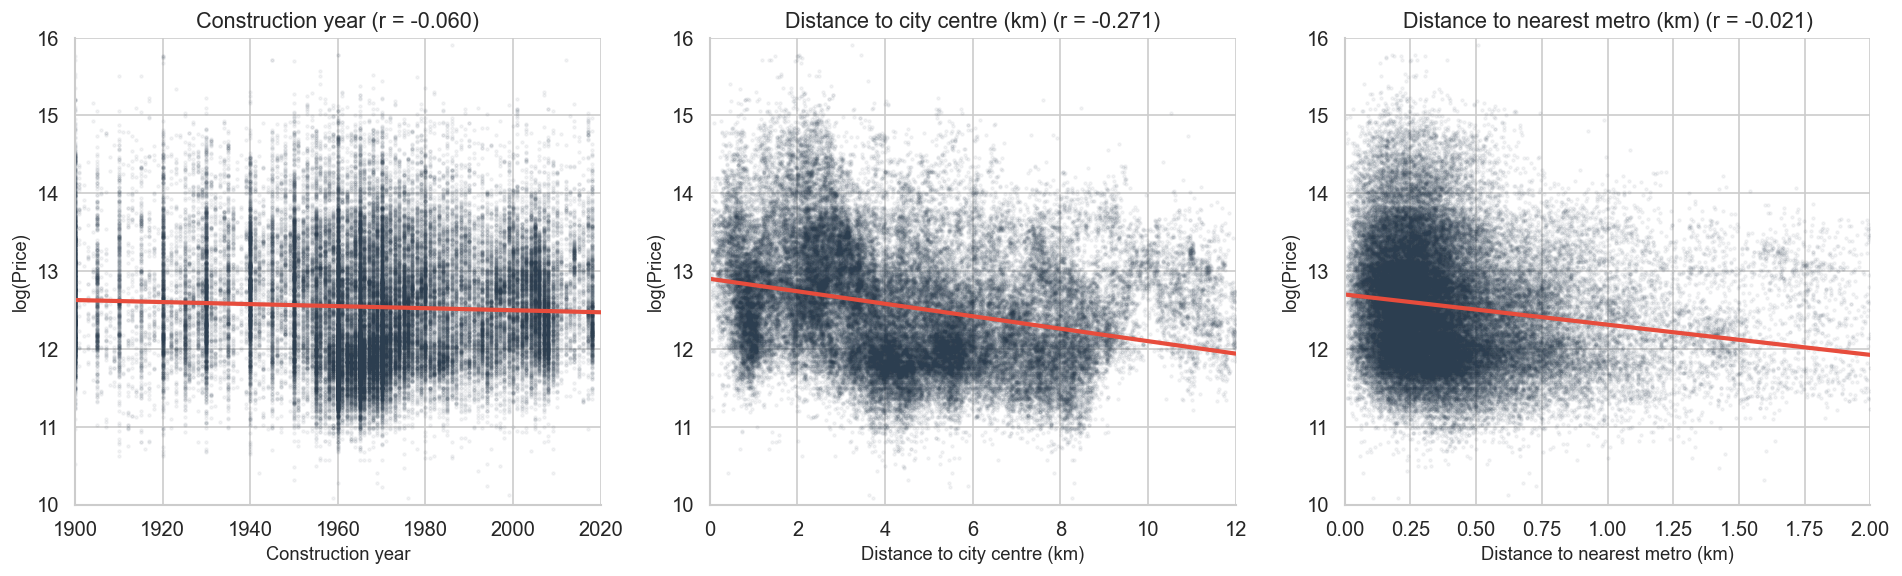

In [4]:
# Remaining continuous features vs log(PRICE)
other_features = ["CADCONSTRUCTIONYEAR", "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

xlims = {
    "CADCONSTRUCTIONYEAR": (1900, 2020),
    "DISTANCE_TO_CITY_CENTER": (0, 12),
    "DISTANCE_TO_METRO": (0, 2),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feat in zip(axes, other_features):
    lo, hi = xlims[feat]
    mask = df[feat].between(lo, hi)
    ax.scatter(df.loc[mask, feat], df.loc[mask, "log_price"], alpha=0.05, s=3, color="#2c3e50")
    z = np.polyfit(df.loc[mask, feat], df.loc[mask, "log_price"], 1)
    x_line = np.linspace(lo, hi, 100)
    ax.plot(x_line, np.polyval(z, x_line), color="#e74c3c", lw=2.5)
    r = df[feat].corr(df["log_price"])
    ax.set_xlim(lo, hi)
    ax.set_ylim(10, 16)
    ax.set_title(f"{readable[feat]} (r = {r:.3f})")
    ax.set_ylabel("log(Price)")
    ax.set_xlabel(readable[feat])
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Key findings:

- CONSTRUCTEDAREA (r = 0.75) is the strongest linear predictor. A linear model can capture most of this relationship directly.
- DISTANCE_TO_CITY_CENTER (r = -0.27) shows a moderate negative effect: closer to the centre means higher price.
- CADCONSTRUCTIONYEAR (r = -0.06) has almost no linear relationship, but the scatter reveals a U-shaped pattern: pre-1900 buildings and post-2000 constructions are more expensive than 1960s-1980s buildings. A linear model will miss this, so we should consider construction-period bins or tree-based models.
- DISTANCE_TO_METRO (r = -0.02) is very weak linearly. Its Spearman correlation (-0.18) is slightly higher, indicating a small monotonic effect.

## 2. Discrete and ordinal features vs log(PRICE)

Boxplots show how the distribution of log(PRICE) changes across levels of each discrete feature. Monotonic relationships suggest ordinal treatment, while non-monotonic ones require categorical encoding or non-linear models.

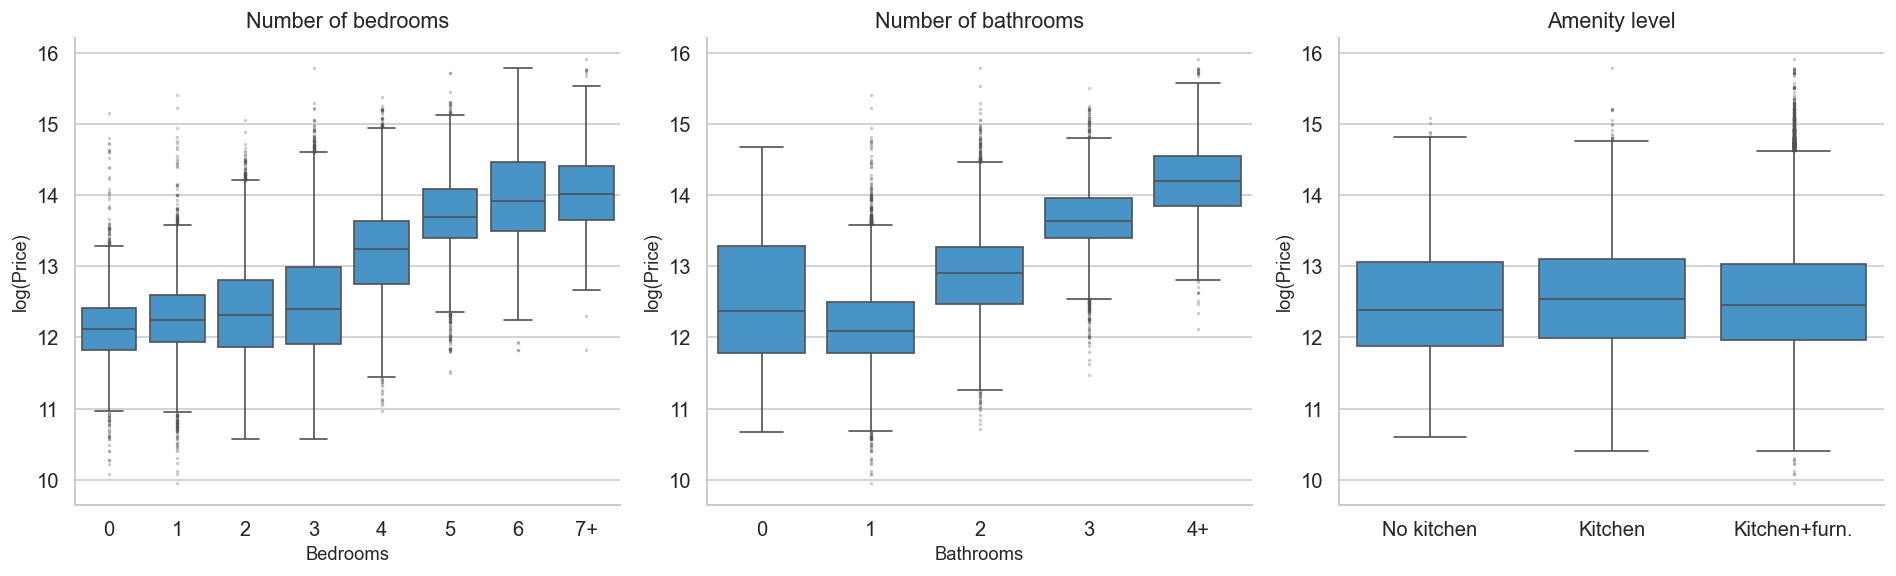

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Bedrooms
room_data = df.copy()
room_data["rooms"] = room_data["ROOMNUMBER"].clip(upper=7).astype(str)
room_data.loc[room_data["ROOMNUMBER"] >= 7, "rooms"] = "7+"
sns.boxplot(x="rooms", y="log_price", data=room_data, ax=axes[0],
            order=[str(i) for i in range(7)] + ["7+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0].set_title("Number of bedrooms")
axes[0].set_xlabel("Bedrooms")

# Bathrooms
bath_data = df.copy()
bath_data["baths"] = bath_data["BATHNUMBER"].clip(upper=4).astype(str)
bath_data.loc[bath_data["BATHNUMBER"] >= 4, "baths"] = "4+"
sns.boxplot(x="baths", y="log_price", data=bath_data, ax=axes[1],
            order=[str(i) for i in range(4)] + ["4+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].set_title("Number of bathrooms")
axes[1].set_xlabel("Bathrooms")

# Amenity level
amenity_labels = {1: "No kitchen", 2: "Kitchen", 3: "Kitchen+furn."}
amenity_data = df.copy()
amenity_data["amenity"] = amenity_data["AMENITYID"].map(amenity_labels)
sns.boxplot(x="amenity", y="log_price", data=amenity_data, ax=axes[2],
            order=["No kitchen", "Kitchen", "Kitchen+furn."], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[2].set_title("Amenity level")
axes[2].set_xlabel("")

for ax in axes:
    ax.set_ylabel("log(Price)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

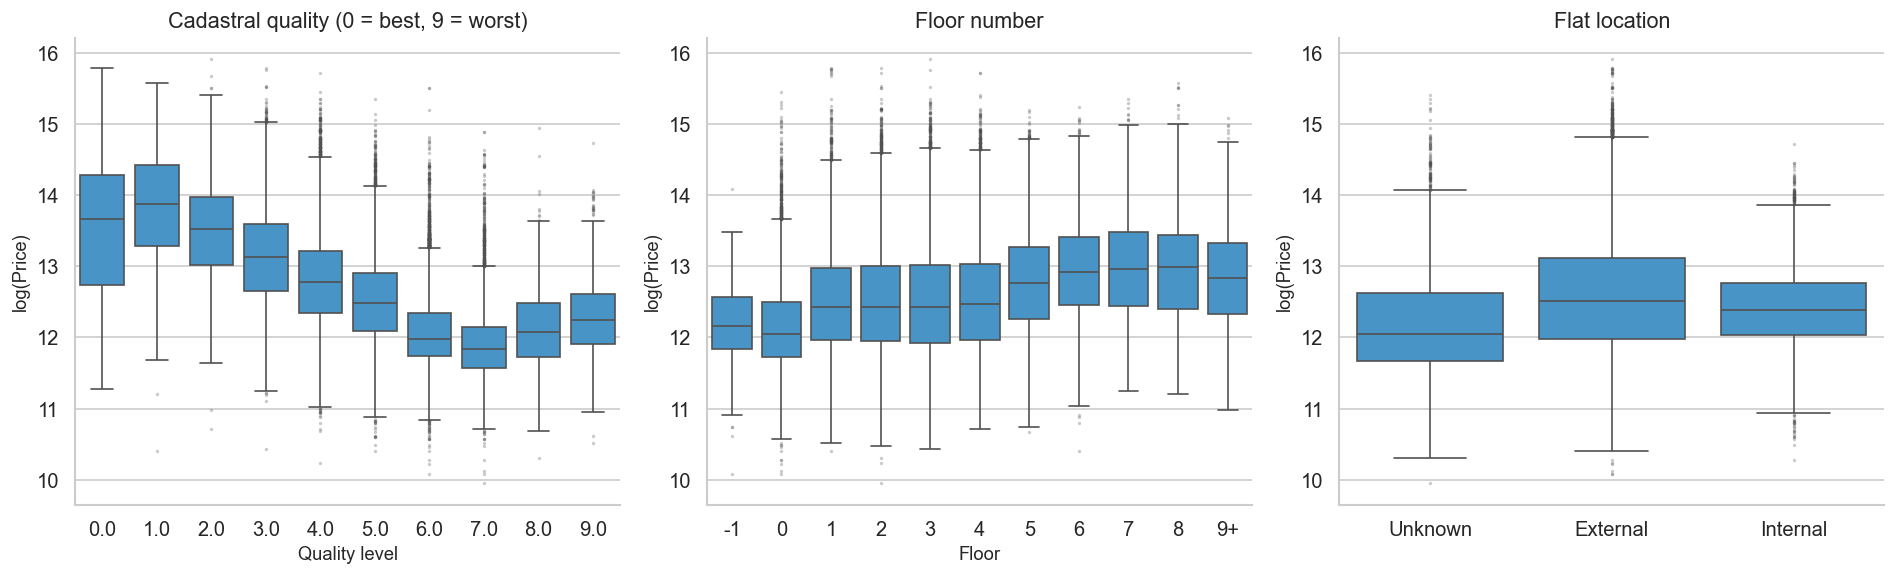

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Cadastral quality
sns.boxplot(x="CADASTRALQUALITYID", y="log_price", data=df, ax=axes[0], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0].set_title("Cadastral quality (0 = best, 9 = worst)")
axes[0].set_xlabel("Quality level")

# Floor number
floor_data = df.copy()
floor_data["floor"] = floor_data["FLOORCLEAN"].clip(-1, 8).astype(int).astype(str)
floor_data.loc[floor_data["FLOORCLEAN"] > 8, "floor"] = "9+"
sns.boxplot(x="floor", y="log_price", data=floor_data, ax=axes[1],
            order=[str(i) for i in range(-1, 9)] + ["9+"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].set_title("Floor number")
axes[1].set_xlabel("Floor")

# Flat location
loc_labels = {0: "Unknown", 1: "External", 2: "Internal"}
loc_data = df.copy()
loc_data["location"] = loc_data["FLATLOCATIONID"].map(loc_labels)
sns.boxplot(x="location", y="log_price", data=loc_data, ax=axes[2],
            order=["Unknown", "External", "Internal"], color="#3498db",
            flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[2].set_title("Flat location")
axes[2].set_xlabel("")

for ax in axes:
    ax.set_ylabel("log(Price)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Key findings:

- BATHNUMBER is a stronger predictor than ROOMNUMBER (r = 0.70 vs 0.46). The price jumps sharply with each additional bathroom, making it one of the top features.
- CADASTRALQUALITYID shows a strong monotonic decrease (r = -0.57): lower quality level means higher price. This ordinal structure makes it directly usable by any model type.
- ROOMNUMBER: price rises slowly from 0 to 3 bedrooms and then jumps sharply from 4 onwards. Part of this effect is driven by size (r with area = 0.65), so the model must separate the two contributions.
- AMENITYID has almost no predictive power (r = -0.01) since 94.1% of listings are level 3. It is a candidate for removal during feature selection.
- FLOORCLEAN: higher floors are more expensive (r = 0.23). The ground floor (0) is the cheapest, even below the basement (-1).
- FLATLOCATIONID: external flats are more expensive than internal ones. Listings coded as 0 (unknown, from notebook 01) are the cheapest group, confirming that the missing indicator carries useful information.

## 3. Binary features vs log(PRICE)

For each binary feature, we compute the percentage difference in median price between listings where the feature is present versus absent. This gives a quick view of the raw premium or discount associated with each amenity.

In [7]:
binary_cols = [c for c in df.columns if c.startswith("HAS") or c.startswith("IS") or c.startswith("BUILTTYPEID")]

price_diff = {}
for col in binary_cols:
    median_0 = df.loc[df[col] == 0, "PRICE"].median()
    median_1 = df.loc[df[col] == 1, "PRICE"].median()
    price_diff[col] = ((median_1 - median_0) / median_0) * 100

price_diff = pd.Series(price_diff).sort_values()

readable_bin = {
    "HASTERRACE": "Terrace", "HASLIFT": "Lift", "HASAIRCONDITIONING": "Air conditioning",
    "HASPARKINGSPACE": "Parking",
    "HASNORTHORIENTATION": "North facing", "HASSOUTHORIENTATION": "South facing",
    "HASEASTORIENTATION": "East facing", "HASWESTORIENTATION": "West facing",
    "HASBOXROOM": "Box room", "HASWARDROBE": "Wardrobe", "HASSWIMMINGPOOL": "Swimming pool",
    "HASDOORMAN": "Doorman", "HASGARDEN": "Garden", "ISDUPLEX": "Duplex",
    "ISSTUDIO": "Studio", "ISINTOPFLOOR": "Top floor",
    "BUILTTYPEID_1": "New development",
    "BUILTTYPEID_2": "Second hand, to restore",
    "BUILTTYPEID_3": "Second hand, good condition",
}
labels = [readable_bin.get(c, c) for c in price_diff.index]

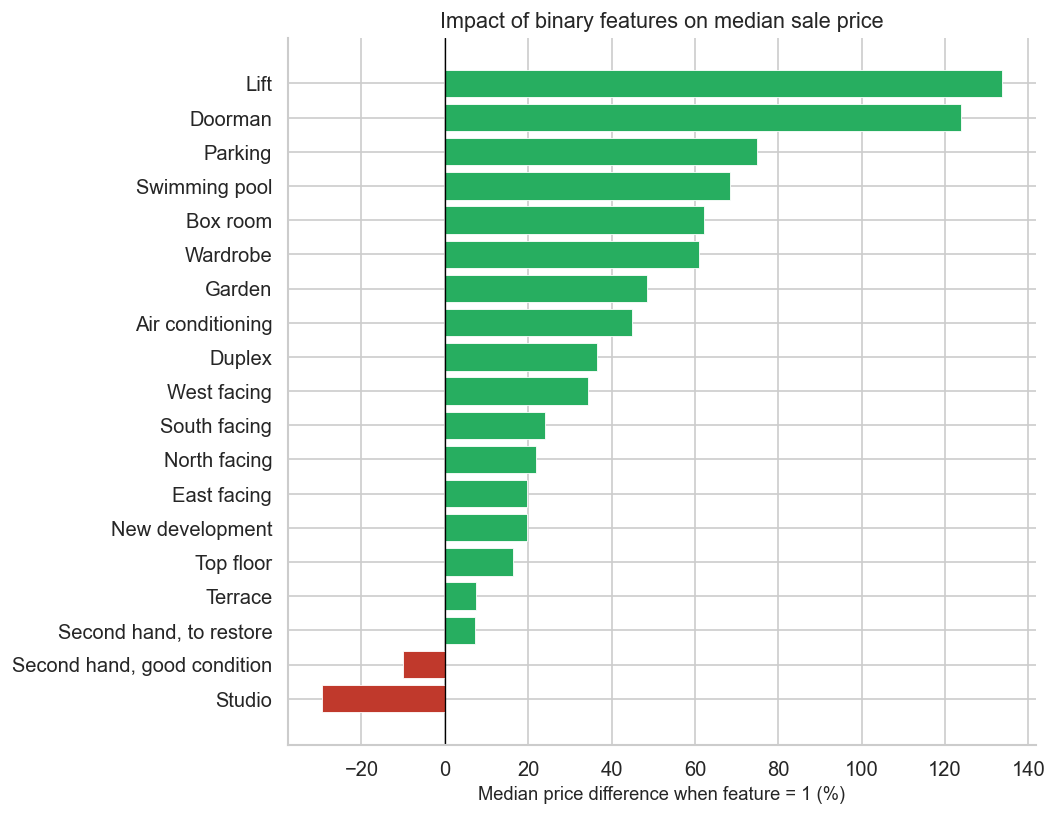

In [8]:
colors = ["#c0392c" if v < 0 else "#27ae60" for v in price_diff]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(labels, price_diff.values, color=colors, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Median price difference when feature = 1 (%)")
ax.set_title("Impact of binary features on median sale price")
ax.axvline(0, color="black", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Key findings:

- Lift (+134%) and doorman (+124%) show the largest raw premiums. These are proxies for building quality: flats without a lift are typically in old walk-up buildings in cheaper areas.
- Parking (+75%), swimming pool (+68%), box room (+62%) and wardrobe (+61%) form a second tier of moderate premiums.
- Studio (-29%) is the strongest discount, as expected for small single-room properties.
- Built type: "to restore" (+7.3%) is surprisingly above "good condition" (-10.0%). This is likely a confounding effect since old flats to restore tend to be in expensive central neighbourhoods.
- Important caveat: these are raw univariate differences, not causal effects. They are confounded with property size and location (for example, pools and gardens co-occur in large homes, r = 0.67). The multivariate model will need to disentangle these effects.

## 4. Correlation matrix

The correlation matrix helps identify which features are most correlated with the target and which pairs of features are highly correlated with each other (multicollinearity), which can destabilise linear models.

In [9]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop("PRICE").tolist()
corr = df[numeric_cols].corr()
target_corr = corr["log_price"].drop("log_price").sort_values()

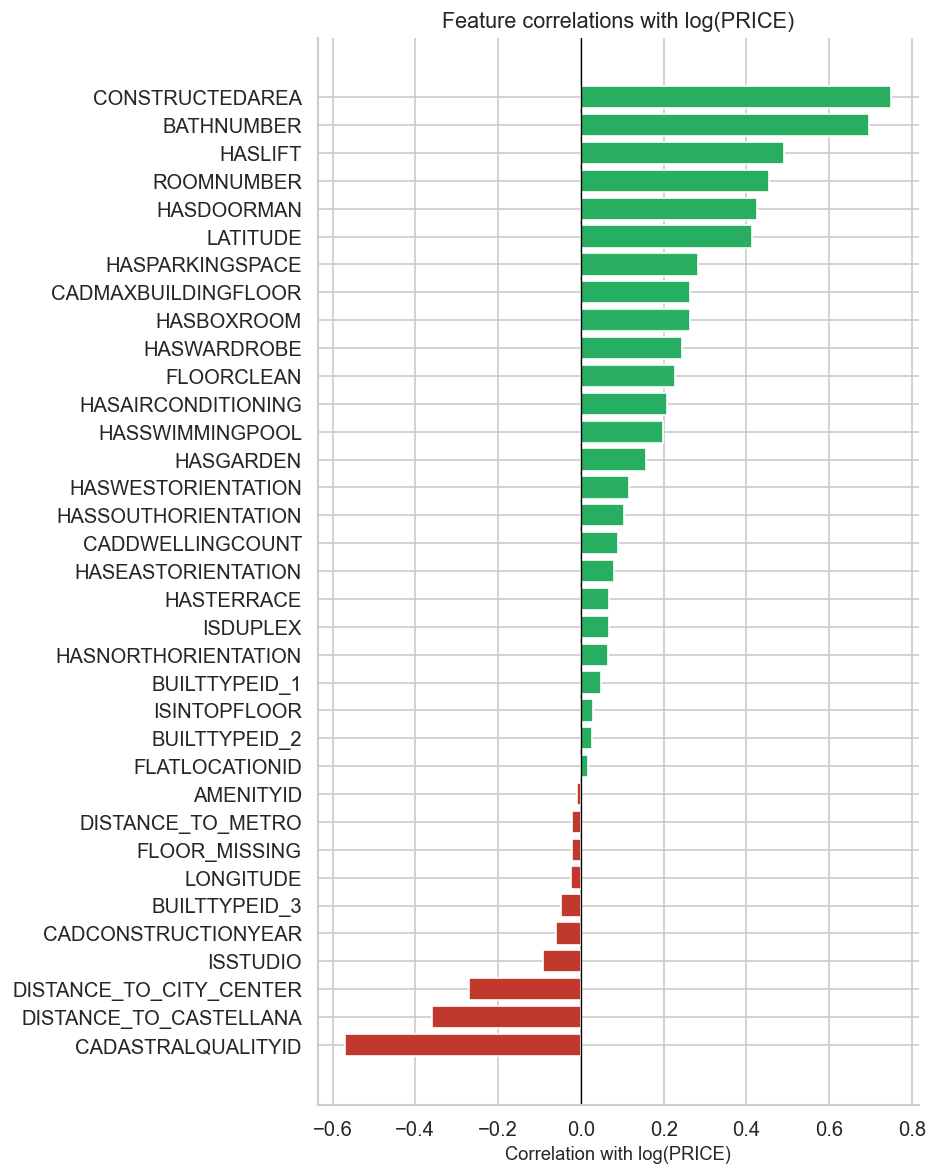

In [10]:
# Correlation of each feature with log(PRICE)
colors = ["#c0392c" if v < 0 else "#27ae60" for v in target_corr.values]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(target_corr.index, target_corr.values, color=colors, edgecolor="white")
ax.set_xlabel("Correlation with log(PRICE)")
ax.set_title("Feature correlations with log(PRICE)")
ax.axvline(0, color="black", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [11]:
# Most correlated pairs of features (multicollinearity risk)
feat_corr = corr.drop(index="log_price", columns="log_price").abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))

print("Most correlated pairs of features:")
print(upper.stack().sort_values(ascending=False).head(6).round(3))

Most correlated pairs of features:
BUILTTYPEID_2            BUILTTYPEID_3             0.906
DISTANCE_TO_CITY_CENTER  DISTANCE_TO_CASTELLANA    0.778
CONSTRUCTEDAREA          BATHNUMBER                0.775
HASSWIMMINGPOOL          HASGARDEN                 0.666
CONSTRUCTEDAREA          ROOMNUMBER                0.652
ROOMNUMBER               BATHNUMBER                0.607
dtype: float64


Top features by absolute correlation with log(PRICE): CONSTRUCTEDAREA (0.75), BATHNUMBER (0.70), CADASTRALQUALITYID (-0.57), HASLIFT (0.49), ROOMNUMBER (0.46), HASDOORMAN (0.43), LATITUDE (0.41), DISTANCE_TO_CASTELLANA (-0.36), HASPARKINGSPACE (0.28) and DISTANCE_TO_CITY_CENTER (-0.27).

Multicollinearity issues to address in modelling:

- BUILTTYPEID_2 and BUILTTYPEID_3 (r = 0.91): one-hot encoding of the same variable. One must be dropped in linear models.
- DISTANCE_TO_CITY_CENTER and DISTANCE_TO_CASTELLANA (r = 0.78): both capture centrality. Consider keeping only one, or let regularisation handle it.
- CONSTRUCTEDAREA, BATHNUMBER, ROOMNUMBER (r = 0.61 to 0.78): correlated size variables. Regularisation (Ridge or Lasso) is needed to stabilise their coefficients.
- HASSWIMMINGPOOL and HASGARDEN (r = 0.67): co-occurring amenities in large properties.

Weak features (absolute r less than 0.07): AMENITYID, FLOOR_MISSING, CADCONSTRUCTIONYEAR, DISTANCE_TO_METRO, LONGITUDE. For CADCONSTRUCTIONYEAR, the low linear correlation hides the U-shaped pattern detected in section 1.

## 5. Geographic and temporal notes

LATITUDE (r = 0.41) captures a clear north-south price gradient: the northern half of Madrid (Salamanca, Chamberi) is more expensive than the south. DISTANCE_TO_CASTELLANA (r = -0.36) is more informative than DISTANCE_TO_CITY_CENTER (r = -0.27). The spatial pattern is non-linear, so tree-based models that can combine latitude and longitude should outperform linear models on this aspect.

The median price per m2 rose 9.2% over 2018 (from 3,260 to 3,560 EUR/m2). This is small compared to cross-sectional variation, but meaningful enough that PERIOD should be included as a control feature.

## 6. Conclusions

### Feature ranking by predictive strength

| Rank | Feature | Relationship with log(PRICE) | Model implication |
|---|---|---|---|
| 1 | CONSTRUCTEDAREA | Positive, linear (r = 0.75) | Directly usable by all model types |
| 2 | BATHNUMBER | Positive (r = 0.70) | Strong but correlated with area; needs regularisation |
| 3 | CADASTRALQUALITYID | Negative, monotonic (r = -0.57) | Ordinal encoding works well |
| 4 | HASLIFT | +134% median premium (r = 0.49) | Building quality proxy |
| 5 | ROOMNUMBER | Positive with jump at 4+ (r = 0.46) | Correlated with area; regularise |
| 6 | HASDOORMAN | +124% median premium (r = 0.43) | Building quality proxy |
| 7 | LATITUDE | North-south gradient (r = 0.41) | Key spatial feature |
| 8 | DISTANCE_TO_CASTELLANA | Negative (r = -0.36) | More informative than distance to centre |
| 9 | HASPARKINGSPACE | +75% median premium (r = 0.28) | Moderate signal |
| 10 | DISTANCE_TO_CITY_CENTER | Negative (r = -0.27) | Correlated with DISTANCE_TO_CASTELLANA |

Non-linear effects not captured by r: CADCONSTRUCTIONYEAR (U-shape) and FLOORCLEAN (ground floor cheapest).

### Final feature set for modelling

Include (30 features): CONSTRUCTEDAREA, ROOMNUMBER, BATHNUMBER, FLOORCLEAN, FLOOR_MISSING, FLATLOCATIONID (categorical with 0 = unknown), CADCONSTRUCTIONYEAR, CADASTRALQUALITYID, CADMAXBUILDINGFLOOR, CADDWELLINGCOUNT, AMENITYID, all HAS/IS binary features, BUILTTYPEID 1/2/3 (drop one in linear models), DISTANCE_TO_CITY_CENTER, DISTANCE_TO_METRO, DISTANCE_TO_CASTELLANA, LATITUDE, LONGITUDE, PERIOD.

Excluded (already dropped in previous notebooks):

- UNITPRICE: target leakage (notebook 01).
- CONSTRUCTIONYEAR: 59% missing, replaced by CADCONSTRUCTIONYEAR (notebook 01).
- PARKINGSPACEPRICE: placeholder values, no information (notebook 01).
- ISPARKINGSPACEINCLUDEDINPRICE: identical to HASPARKINGSPACE (notebook 02).
- ASSETID: identifier with no predictive value.

### Modelling strategy

1. Target transformation: use log(PRICE) as the target. It is approximately normal and linearises the relationship with area and distance features.
2. Baseline model: start with a regularised linear regression (Ridge or Lasso) to establish a baseline and handle multicollinearity.
3. Non-linear models: tree-based models (Random Forest, Gradient Boosting) are expected to outperform linear regression because they can capture the U-shaped construction year effect and the spatial interactions.
4. Multicollinearity handling: in linear models, drop one BUILTTYPEID dummy and consider dropping one of the two distance variables.
5. Train/test split: stratify by PERIOD to ensure each quarter is represented proportionally.
6. Feature selection: AMENITYID, DISTANCE_TO_METRO, and LONGITUDE are candidates for removal if they do not improve model performance.